# JavaScript 基础第四天

函数、作用域与秒数转换

## 课程说明

本日把第三天的循环和数组操作封装成函数：先学声明与调用，再通过参数传入数据、通过返回值取出结果，接着理解作用域和匿名函数，最后完成秒数转换案例。讲义结尾补充逻辑短路和布尔转换。

本篇依据[百度网盘课程资料](https://pan.baidu.com/s/1MxueOHXGQtmE-ypRq1kELA?pwd=9987)中的「JavaScript基础第四天」整理，提取码 `9987`。来源包括 64 页讲义、原 Markdown、XMind、18 份课堂代码、配套素材以及作业题目和答案。正文按课程顺序组织，宣传页和重复总结不重复收录。原 Markdown 的开头提到对象和数学对象，但当天讲义主线是函数，本篇按当天实际内容整理。

标为“课堂原代码”的内容保留原文件的变量、提示和注释状态；通常摘录 HTML 的 `<script>`，九九乘法表保留完整页面以便复现样式。其他示例注明是整理或补充写法，资料疑点就地解释。代码在 Notebook 中作为 Markdown 展示，不在 Python 内核中执行；JavaScript 片段放入 HTML 的 `<script>` 后用浏览器练习，完整页面直接保存成 `.html`。图示直接嵌入笔记。不同示例应分别运行，避免重复声明变量。

## 0. 上节回顾：数组与循环

课堂第一个文件回顾查找索引和收集五个年龄。查找部分已注释，当前启用的是利用数组长度控制输入次数。

课堂原代码（`04-code/01-作业.html`）：

```javascript
    // 找出数组中 元素为10的下标，有则打印该下标，没有则打印 -1
    // let arr = [88, 20, 10, 100, 50]

    // let result = -1
    // for (let i = 0; i < arr.length; i++) {
    //   if (arr[i] === 10) {
    //     result = i
    //   }
    // }
    // 需求1：让用户输入五个有效年龄（0 - 100之间），放入数组中

    //   - 必须输入五个有效年龄年龄，如果是无效年龄，则不能放入数组中
    // arr.length  动态的
    let arr = []
    while (arr.length < 5) {
      let num = +prompt(`请输入第${arr.length + 1}个数据`)
      arr.push(num)
    }  
  
```

**原码的实际行为：**每次输入经一元 `+` 转为数字后直接加入数组，直到数组长度为 `5`；没有验证是否为 `0~100` 的有效年龄，也没有输出结果。空字符串和取消输入会转成 `0`，非法文字会转成 `NaN`。注释中的查找没有 `break`，若存在多个 `10`，会记录最后一个匹配位置；若要第一个位置，找到后就应结束循环。

有效年龄校验与第三天完整作业写法见上一篇。本日把这类操作进一步封装，重点是“输入什么数据、完成什么任务、交出什么结果”。

## 1. 函数的声明与调用

### 1.1 为什么需要函数

**函数是执行特定任务的代码块。**把相同或相似的逻辑放在函数体中，使用时调用，可以减少重复代码，方便修改和复用。之前用过的 `alert()`、`prompt()`、`parseInt()`、`Number()` 和 `console.log()`，都是已有的函数调用。

例如页面需要四张九九乘法表，不必把双重循环复制四遍：声明一次 `sheet99`，再调用四次即可。循环用于一次任务内部的重复操作，函数用于把整个任务包装起来，决定何时执行和执行几次；二者可以配合使用。

### 1.2 声明、函数体与调用

一个函数可以包含声明关键字、函数名、形参、函数体和返回值。参数与显式返回值按需求设置，不是每个函数都必须写。

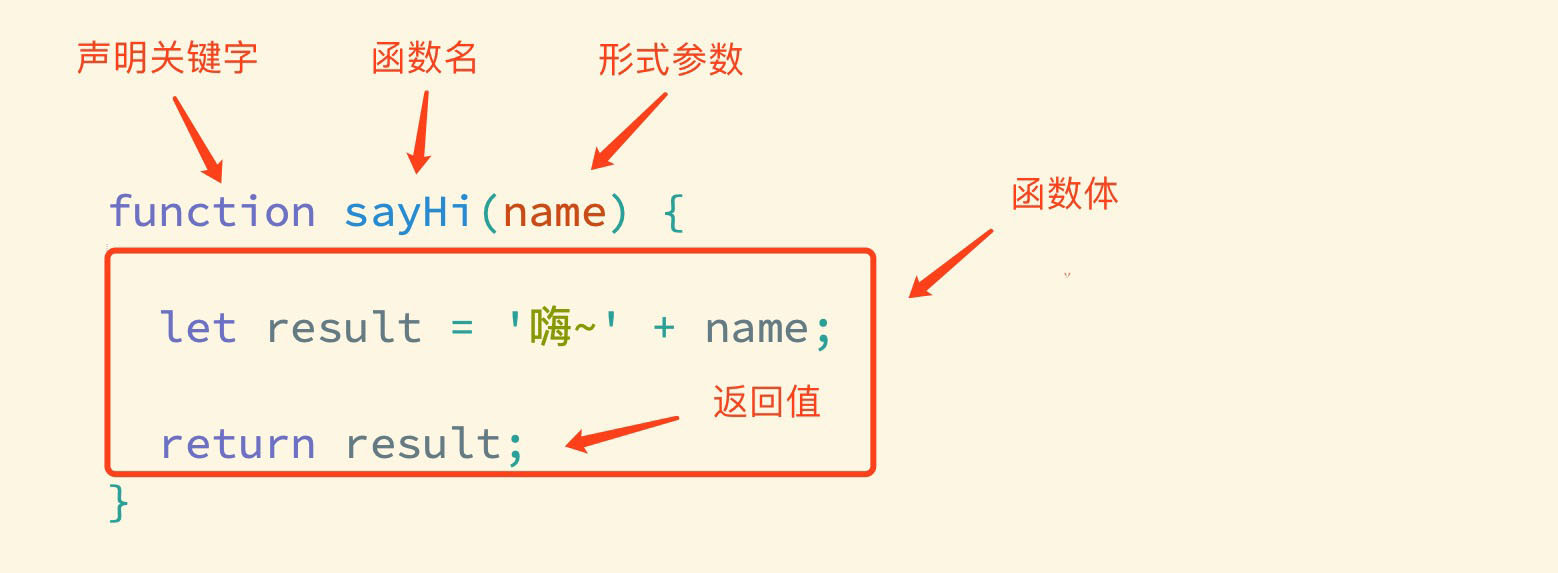

整理示例：

```javascript
function sayHi(name) {
  let result = '嗨~' + name
  return result
}
console.log(sayHi('小明'))  // 嗨~小明
```

`function` 声明函数，`sayHi` 是函数名，`name` 是形参，花括号中的语句是函数体，`return result` 把结果交给调用者。**声明函数不会自动执行函数体，函数名后加 `()` 才是调用。**

课堂原代码（`04-code/03-函数的使用.html`）：

```javascript
    // let num = 10
    // console.log(num)
    // 1. 函数的声明   
    function sayHi() {
      console.log('hi~~~')
    }
    // 2. 函数调用   函数不调用，自己不执行
    sayHi()
    sayHi()
    sayHi()
  
```

原码连续调用三次，控制台输出三次 `hi~~~`。`sayHi` 表示函数本身，`sayHi()` 表示执行这个函数；省略括号不会完成打招呼任务。

### 1.3 函数命名

函数名遵循变量命名规则，通常采用小驼峰，名字应说明要完成的任务，如 `getSum`、`getTime`、`getArrValue`。讲义第 12 页给出以下常用前缀约定：

| 前缀 | 表达的含义 | 命名示例 |
| --- | --- | --- |
| `can` | 是否能执行某个动作 | `canRead` |
| `has` | 是否具有某个值或内容 | `hasValue` |
| `is` | 是否满足某种状态 | `isAdult` |
| `get` | 获取数据 | `getTime` |
| `set` | 设置数据 | `setName` |
| `load` | 加载数据 | `loadData` |

这是便于阅读的约定，并非语法规定。不要用关键字作函数名，也不要把无关功能全部放进一个含义模糊的函数。

### 1.4 体验封装：九九乘法表

讲义要求封装乘法表并重复调用三次，配套文件当前调用四次。下方保留原页面与样式，每次调用生成 `45` 个乘法项和 `9` 次换行，四次共 `180` 个乘法项。

课堂原代码（`04-code/02-体验函数99乘法表.html`）：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8">
  <meta http-equiv="X-UA-Compatible" content="IE=edge">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    span {
      display: inline-block;
      width: 100px;
      padding: 5px 10px;
      border: 1px solid pink;
      margin: 2px;
      border-radius: 5px;
      box-shadow: 2px 2px 2px rgba(255, 192, 203, .4);
      background-color: rgba(255, 192, 203, .1);
      text-align: center;
      color: hotpink;
    }
  </style>
</head>

<body>

  <script>
    // // 1. 外层循环控制行数
    // for (let i = 1; i <= 9; i++) {
    //   // 2. 里层循环控制列数
    //   for (let j = 1; j <= i; j++) {
    //     document.write(`<span>${j} X ${i} = ${i * j}</span>`)
    //   }
    //   // 换行
    //   document.write('<br>')
    // }
    // // 1. 外层循环控制行数
    // for (let i = 1; i <= 9; i++) {
    //   // 2. 里层循环控制列数
    //   for (let j = 1; j <= i; j++) {
    //     document.write(`<span>${j} X ${i} = ${i * j}</span>`)
    //   }
    //   // 换行
    //   document.write('<br>')
    // }
    // // 1. 外层循环控制行数
    // for (let i = 1; i <= 9; i++) {
    //   // 2. 里层循环控制列数
    //   for (let j = 1; j <= i; j++) {
    //     document.write(`<span>${j} X ${i} = ${i * j}</span>`)
    //   }
    //   // 换行
    //   document.write('<br>')
    // }
    // 声明
    function sheet99() {
      for (let i = 1; i <= 9; i++) {
        // 2. 里层循环控制列数
        for (let j = 1; j <= i; j++) {
          document.write(`<span>${j} X ${i} = ${i * j}</span>`)
        }
        // 换行
        document.write('<br>')
      }
    }
    // 调用
    sheet99()
    sheet99()
    sheet99()
    sheet99()
  </script>
</body>

</html>
```

封装步骤是：先确认双重循环能正确绘制一张表，把它放进函数体，再在需要的位置调用函数。要按讲义练习三次，减少一次 `sheet99()` 即可。

### 1.5 封装固定任务：两数求和与累加

讲义第 17 页要求封装两个任务：求两个数的和、求 `1~100` 的累加和。原文件把弹框输入两个数的版本注释了，当前运行的是固定范围累加，结果为 `5050`。

课堂原代码（`04-code/04-函数封装案例.html`）：

```javascript
    // 1. 求2个数的和
    // function getSum() {
    //   let num1 = +prompt('请输入第一个数')
    //   let num2 = +prompt('请输入第二个数')
    //   console.log(num1 + num2)
    // }
    // getSum()
    // 2. 求 1~100 累加和
    function getSum() {
      let sum = 0
      for (let i = 1; i <= 100; i++) {
        sum += i
      }
      console.log(sum)
    }
    getSum()
  
```

固定数据写在函数体内，能复用这个任务，却不能灵活更换计算范围。下一步通过参数，把“每次会变化的数据”从调用处传进去。

## 2. 函数参数

### 2.1 形参、实参与位置对应

声明时括号里的变量叫**形参**，调用时括号里提供的实际数据叫**实参**。多个参数用英文逗号分隔，按位置对应。

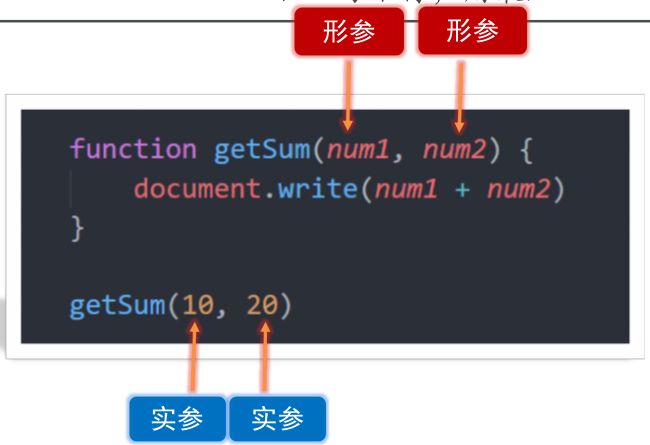

图中 `num1`、`num2` 是形参，`10`、`20` 是实参。调用时相当于给本次函数执行中的两个形参分别赋值。

课堂原代码（`04-code/05-函数参数.html`）：

```javascript
    // 2. 求 1~100 累加和
    // function getSum(end) {   // end = 50
    //   // console.log(end)
    //   let sum = 0
    //   for (let i = 1; i <= end; i++) {
    //     sum += i
    //   }
    //   console.log(sum)
    // }
    // getSum(50)  // 1~50
    // getSum(100)  // 1~100

    function getSum(start, end) {   // end = 50
      // 形参  形式上的参数  
      // console.log(end)
      let sum = 0
      for (let i = start; i <= end; i++) {
        sum += i
      }
      console.log(sum)
    }
    getSum(1, 50)  // 调用的小括号里面 实参 - 实际的参数
    getSum(100, 200)  // 实参 - 实际的参数
  
```

当前函数接收起点 `start` 与终点 `end`，从起点累加到终点，**包括两端**。`getSum(1, 50)` 输出 `1275`，`getSum(100, 200)` 输出 `15150`。原注释 `end = 50` 只对应第一次调用，不代表每次终点都是 `50`。

本例按起点不大于终点的整数区间练习。若起点大于终点，循环一次也不执行，结果是 `0`；顺序传反会改变实际含义。

### 2.2 实参可以是变量

实参可以是直接写出的值，也可以是变量或表达式。用户输入保存在变量里，再将变量当前的值传给函数。

课堂原代码（`04-code/08-实参可以是变量.html`）：

```javascript
    // 求 n ~ m 的累加和
    function getSum(n = 0, m = 0) {
      let sum = 0
      for (let i = n; i <= m; i++) {
        sum += i
      }
      console.log(sum)
    }
    // getSum()
    // getSum(1, 2)
    let num1 = +prompt('请输入起始值:')
    let num2 = +prompt('请输入结束值:')
    // 调用函数
    getSum(num1, num2)  // 实参可以是变量
  
```

输入 `1` 和 `100`，输出 `5050`。`prompt()` 返回字符串，前面的 `+` 把它转换为数字。本例假定输入有效整数且起点不大于终点；默认参数不会替代已经传进来的 `NaN`。

讲义第 24 页的“两数求和并打印到页面”练习，整理写法如下，注意它与上方的**区间累加**是两个任务：

```javascript
function printSum(x, y) {
  document.write(`两数之和是：${x + y}`)
}
let num1 = +prompt('请输入第一个数')
let num2 = +prompt('请输入第二个数')
printSum(num1, num2)
```

输入 `10`、`20` 后，页面显示 `两数之和是：30`。函数只负责处理收到的两个数，输入过程写在调用者一侧。

### 2.3 参数默认值

没有提供某个实参时，对应形参通常是 `undefined`。`1 + undefined` 得到 `NaN`。在声明时写 `形参 = 默认值`，可以为省略参数的调用提供约定值。

课堂原代码（`04-code/06-函数参数-默认参数.html`）：

```javascript
    // 函数求和
    // function getSum(x = 0, y = 0) {
    //   // x = 1
    //   // num1 默认的值 undefined
    //   document.write(x + y)
    // }
    // getSum(1, 2)
    // getSum()  // 0
    function getSum(start = 0, end = 0) {   // end = 50
      // 形参  形式上的参数
      // console.log(end)
      let sum = 0
      for (let i = start; i <= end; i++) {
        sum += i
      }
      console.log(sum)
    }
    getSum(1, 50)  // 调用的小括号里面 实参 - 实际的参数
    getSum(100, 200)  // 实参 - 实际的参数
    getSum()
  
```

原码依次输出 `1275`、`15150`、`0`。最后一次没有实参，`start`、`end` 都取 `0`，循环累加一次数字 `0`。

**补充讲义：默认值在“省略参数”或“显式传入 `undefined`”时生效。**传入 `0`、`false`、`''`、`null` 或 `NaN` 都不会触发默认值。

```javascript
function showValue(value = 10) {
  return value
}
console.log(showValue())           // 10
console.log(showValue(undefined))  // 10
console.log(showValue(0))          // 0
console.log(showValue(false))      // false
console.log(showValue(null))       // null
```

默认值只能处理约定的缺省情况，不能证明参数合法。范围、类型等约束仍由函数需求决定。

### 2.4 封装数组求和

讲义以学生分数数组为例：把数组作为一个参数传入，函数内部遍历、累加，便可复用同一套逻辑处理不同学生的分数。

课堂原代码（`04-code/07-函数封装数组求和.html`）：

```javascript
    // 1. 封装函数
    // 给一个参数的默认值
    function getArrSum(arr = []) {
      // console.log(arr)
      let sum = 0
      for (let i = 0; i < arr.length; i++) {
        sum += arr[i]
      }
      console.log(sum)
    }
    getArrSum([1, 2, 3, 4, 5])
    getArrSum([11, 22, 33])
    getArrSum()  // 0
  
```

三次调用输出 `15`、`66`、`0`。默认参数 `arr = []` 让不传数组时按空数组处理，循环不会执行，`sum` 保持为 `0`。

当前函数通过 `console.log(sum)` 在内部显示结果，**还没有把和返回出去**。如果写 `let total = getArrSum([1, 2, 3])`，控制台会显示 `6`，但 `total` 是 `undefined`。下一节用 `return` 解决这个问题。

## 3. 函数返回值

### 3.1 把结果交给调用者

参数负责把数据送进函数，返回值负责把计算结果交出来。使用 `return 数据` 后，调用表达式的值就是返回的数据，调用者可以保存、输出或继续计算。

课堂原代码（`04-code/09-函数的返回值.html`）：

```javascript
    // // 函数的返回值
    // function fn() {
    //   return 20
    // }
    // // fn() 调用者 相当于执行了    fn()   = 20
    // // return 的值返回给调用者
    // // console.log(fn())
    // // let num = prompt('请输入数字')
    // let re = fn()
    // console.log(re)

    // 求和函数的写法
    function getTotalPrice(x, y) {
      return x + y
      // return 后面的代码不会被执行
    }
    // console.log(getTotalPrice(1, 2))
    // console.log(getTotalPrice(1, 2))
    let sum = getTotalPrice(1, 2)
    console.log(sum)
    console.log(sum)

    function fn() {

    }
    let re = fn()
    console.log(re)  // undefined
  
```

`getTotalPrice(1, 2)` 返回 `3`，变量 `sum` 接收它，随后两次输出都为 `3`。空函数 `fn()` 没有显式返回数据，结果为 `undefined`。

| 写法 | 作用 | 能否代替返回值 |
| --- | --- | --- |
| `console.log(value)` | 显示在控制台 | 不能 |
| `document.write(value)` | 写入当前页面 | 不能 |
| `return value` | 将值交给函数调用者，并结束本次调用 | 可以由调用者接收 |

整理版数组求和把输出改为返回：

```javascript
function getArrSum(arr = []) {
  let sum = 0
  for (let i = 0; i < arr.length; i++) {
    sum += arr[i]
  }
  return sum
}
let total = getArrSum([1, 2, 3, 4, 5])
console.log(total)  // 15
document.write(`总分是：${total}`)
```

这时函数负责计算，调用者决定怎样使用结果。`prompt()` 返回输入内容，`parseInt()` 返回转换结果，也是同一思路。

### 3.2 return 的执行规则

**一个函数可以写多处 `return`，但一次调用执行到第一处 `return` 就结束。**原 Markdown 的“函数内部只能出现一次 return”不准确。例如按分支返回两数中的较大值：

```javascript
function getMax(x, y) {
  if (x > y) {
    return x
  }
  return y
}
console.log(getMax(11, 234))  // 234
console.log(getMax(9, 3))     // 9
```

返回后不会继续执行函数体中的后续语句。`return` 后不接数据，或执行到函数末尾都没有遇到 `return`，该次调用的返回值是 `undefined`。

返回的数据应紧跟 `return`，不要换到下一行。下方是**错误演示**：自动插入分号后，相当于先执行 `return;`，调用结果为 `undefined`。

```javascript
function wrongReturn() {
  return
  10
}
console.log(wrongReturn())  // undefined
```

| 关键字 | 结束的范围 |
| --- | --- |
| `return` | 当前函数调用，即使正在循环中也会退出函数 |
| `break` | 最近的循环或 `switch`，之后仍可执行函数后面的语句 |
| `continue` | 当前这轮循环，继续下一轮 |

### 3.3 求最大值、最小值与返回一组数据

讲义第 34 页要求返回两数最大值、数组最大值和最小值。两数比较可以写成 `return x > y ? x : y`；数组极值需要先设初值，再遍历比较。

课堂文件保留了三个版本，前两个已注释，当前版本把最大值、最小值放入一个数组返回：

课堂原代码（`04-code/10-求最大值函数.html`）：

```javascript
    // 1. 求最大值函数
    // function getMax(x, y) {
    //   return x > y ? x : y
    // }
    // let max = getMax(11, 234)
    // console.log(max)

    // //  2. 求任意数组的最大值，并且返回
    // function getArrValue(arr = []) {
    //   // (1)先准备一个max变量存放数组的第一个值
    //   let max = arr[0]
    //   // (2) 遍历比较
    //   for (let i = 1; i < arr.length; i++) {
    //     if (max < arr[i]) {
    //       max = arr[i]
    //     }
    //   }
    //   // (3) 返回值
    //   return max
    // }

    // // let max = getArrValue([1, 3, 5, 7, 9])
    // // let num = prompt('请输入')
    // let max = getArrValue([11, 3, 55, 7, 29])
    // console.log(max)
    //  3. 求任意数组的最大值和最小值，并且返回
    function getArrValue(arr = []) {
      // (1)先准备一个max变量存放数组的第一个值
      let max = arr[0]
      let min = arr[0]  // 最小值
      // (2) 遍历比较
      for (let i = 1; i < arr.length; i++) {
        // 最大值
        if (max < arr[i]) {
          max = arr[i]
        }
        // 最小值
        if (min > arr[i]) {
          min = arr[i]
        }
      }
      // (3) 返回值  返回的是数组
      return [max, min]
      // return min
    }
    let newArr = getArrValue([11, 3, 55, 7, 29])
    console.log(`数组的最大值是: ${newArr[0]}`)
    console.log(`数组的最小值是: ${newArr[1]}`)
  
```

`[11, 3, 55, 7, 29]` 返回 `[55, 3]`，`newArr[0]` 取最大值，`newArr[1]` 取最小值。**这里返回的是一个数组，数组中装了两个结果。**连续写 `return max`、`return min` 无法在同一次调用中返回两项，第二处不会执行。

把初值设为 `arr[0]`，可以正确处理全负数数组；若最大值一开始设为 `0`，全负数数组会产生错误结果。这个课堂版本要求数组非空且元素为有效数字；默认空数组会返回 `[undefined, undefined]`，不代表有最大值和最小值。

单独求最小值的整理练习如下：

```javascript
function getArrMin(arr) {
  let min = arr[0]
  for (let i = 1; i < arr.length; i++) {
    if (arr[i] < min) {
      min = arr[i]
    }
  }
  return min
}
console.log(getArrMin([11, 3, 55, 7, 29]))  // 3
```

调试时可在调用处打断点，用 `F11` 进入函数，观察形参取值、极值更新与返回给调用者的过程。

### 3.4 函数细节：参数个数与重名

实参与形参个数不一致在语法上可以执行，但要明确含义。课堂当前启用的是少传一个参数的演示：

课堂原代码（`04-code/11-函数细节.html`）：

```javascript
    // function getSum(x, y) {
    //   return x + y
    //   // 返回值返回给了谁？ 函数的调用者  getSum(1, 2)
    //   // getSum(1, 2) = 3
    // }
    // // let result = getSum(1, 2) = 3
    // // let num = parseInt('12px')
    // let result = getSum(1, 2)
    // console.log(result)
    // 1. 函数名相同， 后面覆盖前面

    // function fn() {
    //   console.log(1)
    // }
    // function fn() {
    //   console.log(2)
    // }
    // fn()
    // 2. 参数不匹配

    function fn(a, b) {
      console.log(a + b)
    }
    // (1). 实参多余形参   剩余的实参不参与运算
    // fn(1, 2, 3)
    // (2). 实参少于形参   剩余的实参不参与运算
    fn(1)   // 1 + undefined  = NaN 
  
```

`fn(1)` 中 `a = 1`，`b = undefined`，执行 `a + b` 得到 `NaN`。原注释称剩余形参“不参与运算”不准确，`b` 仍参与运算，只是值为 `undefined`。

多传实参时，例如 `fn(1, 2, 3)`，第三项没有对应的命名形参，当前函数只使用 `a`、`b`，因此输出 `3`。普通函数内部还可通过 `arguments` 获取传入的实参，本日了解即可。

原码重名函数演示已注释。在同一作用域的普通函数声明中，后面的同名声明可以覆盖前面的声明；实际编写时应避免重名。不要把这条规则泛化到所有写法，例如同一作用域重复 `let fn` 会直接产生语法错误。

## 4. 作用域与变量访问

### 4.1 全局作用域与函数作用域

**作用域是一个名字能够被访问的代码范围。**作用域让函数内部的变量留在自己的范围内，减少命名冲突。本日先学习普通浏览器脚本的全局作用域与函数作用域。

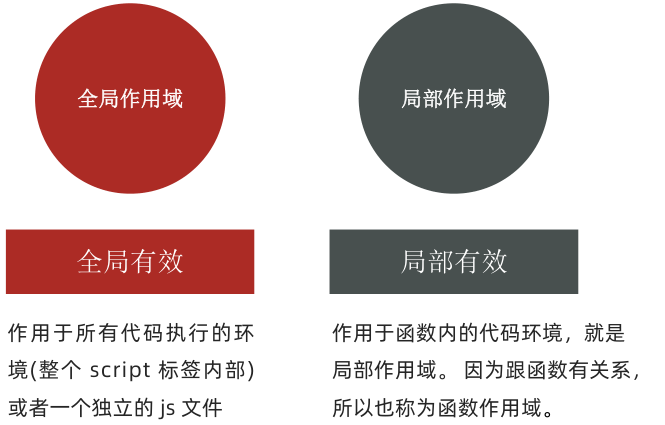

| 类型 | 本日常见写法 | 访问方式 |
| --- | --- | --- |
| 全局变量 | 函数外声明的变量 | 所属脚本环境内的函数可访问，注意同名局部变量遮蔽 |
| 局部变量 | 函数内部声明的变量 | 在所属函数及可访问它的嵌套函数中使用 |
| 形参 | 函数声明时的参数 | 属于函数内部的局部变量 |

课堂原代码（`04-code/12-作用域.html`）：

```javascript
    let num = 10  // 1. 全局变量
    console.log(num)
    function fn() {
      console.log(num)
    }
    fn()

    // 2. 局部变量
    function fun() {
      let str = 'pink'
    }
    console.log(str)  // 错误
  
```

**这是故意报错的课堂演示。**前面两次输出都是 `10`，说明函数可以访问外层全局变量。`str` 只在 `fun()` 内部声明，外部的 `console.log(str)` 抛出 `ReferenceError: str is not defined`，本次脚本执行到这里停止。即使先调用 `fun()`，也不会让局部变量自动变为全局变量。

需要在外部使用局部计算结果时，通过返回值传出来，整理写法：

```javascript
function fun() {
  let str = 'pink'
  return str
}
let result = fun()
console.log(result)  // pink
```

### 4.2 形参、外层变量与未声明赋值

课堂原代码（`04-code/13-变量的特殊情况.html`）：

```javascript
    // let num = 20
    // function fn() {
    //   num = 10  // 全局变量来看  强烈不允许
    // }
    // fn()
    // console.log(num)

    // function fun(x, y) {
    //   // 形参可以看做是函数的局部变量
    //   console.log(x)
    // }
    // fun(1, 2)
    // console.log(x)  // 错误的

    // let num = 10
    function fn() {
      // let num = 20
      function fun() {
        // let num = 30
        console.log(num)
      }
      fun()
    }
    fn()
  
```

**原码当前也会报错：**三处 `num` 声明均被注释，最内层 `console.log(num)` 找不到这个名字，抛出 `ReferenceError`。单独启用全局 `num = 10`、外层局部 `num = 20`、内层局部 `num = 30`，可观察查找顺序；若三处都启用，最内层输出 `30`。

函数的形参也是局部变量。原文件注释中的 `fun(x, y)` 接收 `1`、`2` 后，在内部能访问 `x`，外部直接访问 `x` 会报错。

**补充原注释：**函数内部写 `num = 10`，并不必然创建全局变量。如果外层已经声明了 `num`，这句会修改能访问到的那个变量；如果所有可见作用域都没有声明这个名字，非严格普通脚本可能创建全局属性，严格模式会报错。编写变量时应明确声明，不依赖未声明赋值。

整理示例展示“修改已声明的外层变量”：

```javascript
let num = 20
function changeNum() {
  num = 10
}
changeNum()
console.log(num)  // 10
```

### 4.3 就近原则与作用域链

访问变量时，从当前作用域开始查找，找不到就到外层，逐层向外，直到全局；找到了就使用那个变量，不继续寻找同名变量。这里的“外层”由**函数定义所在的代码嵌套关系**决定。

讲义第 44 页示例，内层没有 `num`，使用外层函数的 `123`：

```javascript
function f1() {
  let num = 123
  function f2() {
    console.log(num)
  }
  f2()
}
let num = 456
f1()  // 123
```

第 45 页在 `f2()` 中添加 `let num = 0` 后，输出就变成 `0`：

```javascript
function f1() {
  let num = 123
  function f2() {
    let num = 0
    console.log(num)
  }
  f2()
}
let num = 456
f1()  // 0
```

第 46 页多层嵌套练习，`a` 在当前函数就能找到，`b` 要向外找到 `fn1`：

```javascript
let a = 1
function fn1() {
  let a = 2
  let b = '22'
  fn2()
  function fn2() {
    let a = 3
    fn3()
    function fn3() {
      let a = 4
      console.log(a)  // 4
      console.log(b)  // '22'
    }
  }
}
fn1()
```

不要把就近原则理解成“在调用它的地方找变量”。下面是补充辨析，`show` 定义在全局，读取的是全局 `10`，不会读到 `callShow` 的局部 `20`：

```javascript
let value = 10
function show() {
  console.log(value)
}
function callShow() {
  let value = 20
  show()
}
callShow()  // 10
```

### 4.4 补充：块作用域与初始化前访问

讲义本日主要区分全局与函数作用域，但 `let`、`const` 还具有块作用域。`if`、`for` 或独立花括号中的这类变量，通常只在对应块及其内部可访问。

```javascript
let num = 10
if (true) {
  let num = 20
  console.log(num)  // 20
}
console.log(num)  // 10
```

如果当前作用域已经声明了同名 `let` 变量，却在它初始化前访问，会报错；不会跳过它去读取外层变量。下方是**错误演示**：

```javascript
let num = 10
function demo() {
  console.log(num)  // ReferenceError：访问发生在局部 num 初始化前
  let num = 20
}
demo()
```

记忆：可见范围、查找顺序、初始化时机是三个需要一起考虑的问题。

## 5. 匿名函数

### 5.1 函数表达式

匿名函数没有显式函数名。本日介绍两种使用方式：把函数作为值赋给变量，再调用；或创建后立即执行。不能把孤立的 `function () {}` 当成普通函数声明直接写在语句位置。

课堂函数表达式文件故意先调用、后初始化：

课堂原代码（`04-code/14-函数表达式.html`）：

```javascript
    // console.log(num)
    // let num = 10

    // 3 + 4
    // num = 10
    // 1. 函数表达式
    fn(1, 2)  //错误
    let fn = function (x, y) {
      // console.log('我是函数表达式')
      console.log(x + y)
    }

    // 函数表达式和 具名函数的不同   function fn() {}
    // 1. 具名函数的调用可以写到任何位置
    // 2. 函数表达式，必须先声明函数表达式，后调用
    // function fun() {
    //   console.log(1)
    // }
    // fun()
  
```

**当前代码抛出 `ReferenceError`，不会输出 `3`。**变量 `fn` 使用 `let`，调用发生在初始化之前。正确的整理顺序是先完成赋值，再调用：

```javascript
let fn = function (x, y) {
  console.log(x + y)
}
fn(1, 2)  // 3
```

| 写法 | 示例 | 调用时机 |
| --- | --- | --- |
| 函数声明 | `function fn() {}` | 在所属作用域中，可以在声明语句之前调用 |
| 函数表达式 | `let fn = function () {}` | 必须在变量完成初始化后调用 |

原注释的“具名函数可以写到任何位置”应理解为这里的函数声明提升规则；仍要遵守作用域和函数内部所用变量的初始化时机。函数表达式也可以传参和返回数据，后续 Web API 课程会继续使用。

### 5.2 立即执行函数

立即执行函数（IIFE）把函数表达式放入括号，再立即调用。课堂展示两种等价形式：

课堂原代码（`04-code/15-立即执行函数.html`）：

```javascript
    // let num = 10
    // let num = 20
    // (function () {
    //   console.log(11)
    // })()

    // (function () {
    //   let num = 10
    // })();
    // (function () {
    //   let num = 20
    // })();
    // 1. 第一种写法
    (function (x, y) {
      console.log(x + y)
      let num = 10
      let arr = []
    })(1, 2);
    // (function(){})();
    // 2.第二种写法
    // (function () { }());
    (function (x, y) {
      let arr = []
      console.log(x + y)
    }(1, 3));


    // (function(){})()
    // (function(){}())
  
```

原码输出 `3`、`4`。第一种写法的调用括号位于外括号之后，第二种位于外括号里面：

```javascript
(function () {
  let num = 10
  console.log(num)
})();
(function () {
  let num = 20
  console.log(num)
}());
```

两个函数各有自己的局部变量 `num`，互不冲突。**立即执行函数已经用 `()` 完成调用，不需要再另写一行函数名调用。**连续使用时以分号隔开，避免后一对括号被解释为前一表达式的继续调用。

配套 `06-素材/flexible.js` 的整体结构也是立即执行函数，内部变量与工具函数保存在自己的函数作用域。它的外层函数显式命名为 `flexible`，说明立即执行函数也可以有名字。核心结构摘录如下，中间省略了字体与屏幕尺寸适配逻辑：

```javascript
(function flexible(window, document) {
  var docEl = document.documentElement
  var dpr = window.devicePixelRatio || 1
  // 此处省略原文件中的页面适配逻辑
}(window, document))
```

此处认识函数包裹和参数传入即可；其中 `|| 1` 的回退含义在后文说明。

## 6. 综合案例：秒数转换

### 6.1 需求与计算公式

用户输入总秒数，函数计算小时、分钟、秒，给不足两位的数字补 `0`，返回格式化文字，再显示到页面。

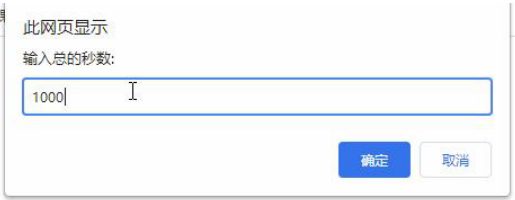

讲义第 57 页公式：

| 部分 | 原公式 | 含义 |
| --- | --- | --- |
| 小时 `h` | `parseInt(t / 60 / 60 % 24)` | 转为小时，再按一天的 24 小时取余 |
| 分钟 `m` | `parseInt(t / 60 % 60)` | 转为分钟，取当前小时内的分钟 |
| 秒 `s` | `parseInt(t % 60)` | 取当前分钟内的秒 |

本课堂案例按有效的非负整数秒数练习。`parseInt` 在这里用于截去计算结果的小数部分，得到整数。输入 `1000`：小时为 `0`，分钟为 `16`，秒为 `40`，补零后为 `00小时16分40秒`。

### 6.2 课堂原码与局部变量报错

课堂原代码（`04-code/16-综合案例.html`）：

```javascript
    // age = age + 1
    // 1. 用户输入
    let second = +prompt('请输入秒数:')
    // 2.封装函数
    function getTime(t) {
      // console.log(t)  // 总的秒数
      // 3. 转换
      // 小时：  h = parseInt(总秒数 / 60 / 60 % 24)
      // 分钟：  m = parseInt(总秒数 / 60 % 60)
      // 秒数: s = parseInt(总秒数 % 60) 
      let h = parseInt(t / 60 / 60 % 24)
      let m = parseInt(t / 60 % 60)
      let s = parseInt(t % 60)
      h = h < 10 ? '0' + h : h
      m = m < 10 ? '0' + m : m
      s = s < 10 ? '0' + s : s
      // console.log(h, m, s)
      return `转换完毕之后是${h}小时${m}分${s}秒`
    }
    let str = getTime(second)
    document.write(str)
    console.log(h)
  
```

函数内部的 `h`、`m`、`s` 先计算为数字，不足 `10` 时用 `'0' + 值` 拼接为两位字符串，最终返回完整文字。外部变量 `str` 接收返回值，`document.write(str)` 显示结果。

**原码最后一行会报错：**`h` 是 `getTime()` 的局部变量，外部 `console.log(h)` 抛出 `ReferenceError: h is not defined`。报错前页面输出已经完成；错误发生在额外访问局部变量时。外部应使用返回值 `str`，或让函数返回需要的数据，不能直接使用内部名字。

原函数参数是 `t`，并没有默认值。讲义分析提到“注意默认值”，下节整理版补充默认参数，避免把原文件未写的内容当作已有代码。

### 6.3 可运行整理版

整理版移除外部对 `h` 的非法访问，并给 `t` 设置默认值 `0`。计算规则与课堂一致：

```javascript
let second = +prompt('请输入秒数:')
function getTime(t = 0) {
  let h = parseInt(t / 60 / 60 % 24)
  let m = parseInt(t / 60 % 60)
  let s = parseInt(t % 60)
  h = h < 10 ? '0' + h : h
  m = m < 10 ? '0' + m : m
  s = s < 10 ? '0' + s : s
  return `转换完毕之后是${h}小时${m}分${s}秒`
}
let str = getTime(second)
document.write(str)
console.log(str)
```

| 输入秒数 | 时分秒部分 |
| --- | --- |
| `0` | `00小时00分00秒` |
| `1000` | `00小时16分40秒` |
| `3661` | `01小时01分01秒` |
| `86399` | `23小时59分59秒` |
| `86400` | `00小时00分00秒` |

默认参数让 `getTime()`、`getTime(undefined)` 按 `0` 处理。它不会处理 `NaN`：弹框输入非法文字经 `+` 转换后是 `NaN`，继续计算也会得到 `NaN`；空输入或取消经 `+` 转换后为 `0`。本例的输入有效性前提仍然存在。

### 6.4 按一天拆分与累计时长的区别

原公式中的 `% 24` 把小时限制在 `0~23`，因此 `86400` 秒会显示 `00小时`。这是按一天周期拆分，适用于只取一天内的时分秒；不能直接作为“累计已经过了多少小时”的结果。

如果需求是累计时长，将小时那行改为下方写法，分钟和秒的公式保持原样：

```javascript
let t = 90061
let h = parseInt(t / 3600)
let m = parseInt(t / 60 % 60)
let s = parseInt(t % 60)
console.log(h, m, s)  // 25 1 1
```

这样 `90061` 秒是累计 `25小时01分01秒`；按课堂 `% 24` 公式则是 `01小时01分01秒`。先明确需求，再选公式。

## 7. 逻辑短路与类型转换

### 7.1 &&、|| 的短路规则

逻辑运算从左往右求值。已经能确定结果时，不再执行后面的表达式，这就是短路，也叫逻辑中断。

| 运算符 | 何时跳过右侧 | 返回什么值 |
| --- | --- | --- |
| `&&` | 左侧是假值 | 返回遇到的第一个假值；全是真值时返回最后一项 |
| `\|\|` | 左侧是真值 | 返回遇到的第一个真值；全是假值时返回最后一项 |

**结果是实际被选中的值，不一定是布尔值。**整理示例：

```javascript
console.log(false && 22)  // false
console.log(11 && 22)     // 22
console.log(0 && 22)      // 0
console.log(true || 22)   // true
console.log(11 || 22)     // 11
console.log(0 || 22)      // 22

let age = 18
console.log(false && age++)  // false，右侧不执行
console.log(age)             // 18
console.log(true || age++)   // true，右侧不执行
console.log(age)             // 18
```

左侧已经短路时，右侧不仅不参与结果，也不会执行它的函数调用、赋值或自增等操作。实际判断左侧是否为真时使用布尔转换，并不限于字面量 `true`、`false`。

### 7.2 使用 || 提供回退值

课堂原代码（`04-code/17-逻辑中断.html`）：

```javascript
    function fn(x, y) {
      x = x || 0
      y = y || 0
      console.log(x + y)
    }
    fn(1, 2)
    // fn()

    // console.log(false && 22)
    // console.log(false && 3 + 5)
    // let age = 18
    // console.log(false && age++) // age++ 不执行  一假则假
    // console.log(age)

    // console.log(true || age++)
    // console.log(age)


    // console.log(11 && 22)  // 都是真，这返回最后一个真值
    // console.log(11 || 22)  //  输出第一个真值
  
```

当前调用 `fn(1, 2)` 输出 `3`。`x = x || 0` 的含义是：`x` 为真值就保留，`x` 为假值就改用 `0`；因此启用 `fn()` 时两个 `undefined` 都会回退到 `0`，输出 `0`。

| 传入值 | 默认参数 `value = 10` | `value \|\| 10` |
| --- | --- | --- |
| 省略或 `undefined` | `10` | `10` |
| `0` | 保留 `0` | `10` |
| `false` | 保留 `false` | `10` |
| `''` | 保留空字符串 | `10` |
| `null` | 保留 `null` | `10` |
| `NaN` | 保留 `NaN` | `10` |

两种写法处理的范围不同。合法输入可能是 `0`、`false` 或空字符串时，不能随意用 `||` 替换参数默认值。在原求和例中回退值也是 `0`，传入 `0` 后数值看起来没变，但短路规则仍然成立。

素材中的 `var dpr = window.devicePixelRatio || 1`，表示左侧值为真时取设备像素比，否则回退为 `1`。讲义第 60 页借这个实际代码同时复习立即执行函数与逻辑短路。

### 7.3 Boolean 显式转换与条件判断

`Boolean(内容)` 把值转换成布尔值。本日常见假值是 `false`、`0`、`''`、`undefined`、`null`、`NaN`；`-0` 也是假值。

课堂原代码（`04-code/18-转换为布尔型.html`）：

```javascript
    console.log(Boolean('pink'))
    console.log(Boolean(''))
    console.log(Boolean(0))
    console.log(Boolean(90))
    console.log(Boolean(-1))
    console.log(Boolean(undefined))
    console.log(Boolean(null))
    console.log(Boolean(NaN))

    console.log('--------------------------')
    let age
    if (age) {
      console.log(11)
    }
  
```

原码依次输出 `true、false、false、true、true、false、false、false`，再输出分隔字符串。`let age` 未赋值，值为 `undefined`，`if (age)` 的条件为假，因此不会输出 `11`。

注意区分“内容看起来像假”与“这个值转换后为假”：

```javascript
console.log(Boolean('0'))      // true
console.log(Boolean('false'))  // true
console.log(Boolean(' '))      // true，包含空格的非空字符串
console.log(Boolean([]))       // true，空数组
console.log(Boolean({}))       // true，空对象
console.log(Boolean(false))    // false，布尔值
```

数组和对象本身是真值，不表示里面一定有内容；后续需要检查内容时，应使用相应的数据检查方式。

### 7.4 复习其他隐式转换

讲义第 62 页标题沿用“转换为 Boolean 型”，但该页实际举的是字符串与数字转换，应分开理解：

```javascript
console.log('' + 1)       // '1'：字符串拼接
console.log('' - 1)       // -1：空字符串转换为数字 0
console.log(null - 1)     // -1：null 转为数字 0
console.log(undefined - 1)  // NaN：undefined 转为数字 NaN
console.log(Number(null))       // 0
console.log(Number(undefined))  // NaN
```

加法遇到字符串可能拼接；减法会把这些操作数转换成数字。弹框输入需要做加法时，先用 `+prompt(...)` 或 `Number(...)` 转数字，避免把 `10` 和 `20` 拼成 `'1020'`。布尔转换与数字转换规则不同，例如空数组 `Boolean([])` 为 `true`，不应据此推断它的数字结果。

## 8. 配套作业：题目、思路与参考

本日共有五道基础题、两道拓展题和两道排错题。先独立尝试，再对照参考与解释。客观题使用资料提供的[第四天作业链接](https://ks.wjx.top/vm/mC2UvoL.aspx#)。讲义复习页把目录写为“06-作业”，实际资料中的目录为 `05-作业`。

### 8.1 基础题一：说明函数执行流程

题目要求说明以下代码的流程，原题代码：

作业题目：

```javascript
function printfInput(content) { 
    // 将用户输入的内容, 在页面中显示
    document.write(content)
}
let constr = prompt('请输入内容')
printfInput(constr)
```

执行过程：

1. 声明 `printfInput`，此时不执行函数体。
2. `prompt('请输入内容')` 获取用户输入，返回的字符串保存在 `constr`。
3. 调用 `printfInput(constr)`，把变量的当前值作为实参传给形参 `content`。
4. 执行函数体的 `document.write(content)`，页面显示输入内容。
5. 函数执行结束，没有显式 `return`，返回值为 `undefined`。

输出到页面和返回给调用者是两件事，不能把页面显示的文字当成这个函数的返回值。

### 8.2 基础题二：两数求和并返回

要求：函数名为 `sum`，接收两个数，必须用 `return` 返回和。资料参考答案：

参考答案：

```javascript
function sum(x, y) {
  let res = x + y
  return res
  // return x + y
}
let te = sum(1, 2)
document.write(`两者的和是${te}`)
```

`sum(1, 2)` 返回 `3`，变量 `te` 接收结果，页面显示 `两者的和是3`。也可以直接写 `return x + y`；原参考中这行作为注释保留，不会被执行。两个参数按数字传入，字符串实参会改变 `+` 的含义。

### 8.3 基础题三：在函数内交换两个值

要求：声明 `changeNum(x, y)`，通过临时变量交换两个形参，再显示结果，可以多次调用。资料参考答案：

参考答案：

```javascript
function changeNum(x,y) { 
   
     let temp = x
     x = y 
     y = temp 
    document.write(`第一个值的结果是${x} <br> 第二个值的结果是${y}`)
}
changeNum(3,4)
changeNum('pink', 'red')
```

交换顺序为 `temp = x`、`x = y`、`y = temp`。参考调用 `changeNum(3, 4)` 输出第一个值为 `4`、第二个值为 `3`；字符串示例交换后为 `'red'`、`'pink'`。按题目调用 `changeNum(1, 2)`，则显示 `2`、`1`。

**这里交换的是函数内部的形参值。**若外部有两个数字变量，将它们传进来不会自动交换外部变量，补充演示：

```javascript
let a = 1
let b = 2
function swap(x, y) {
  let temp = x
  x = y
  y = temp
  return [x, y]
}
let values = swap(a, b)
console.log(a, b)          // 1 2，外部变量尚未改变
a = values[0]
b = values[1]
console.log(a, b)          // 2 1，外部明确接收交换结果
```

### 8.4 基础题四：封装银行卡余额函数

要求：在函数内依次询问银行卡余额、当月食宿消费和当月生活消费，返回剩余余额；调用后在页面显示。资料参考答案：

参考答案：

```javascript
function result() {
  let a = prompt('银行卡金额')
  let b = prompt('当月食宿消费金额?')
  let c = prompt('当月生活消费金额?')
  let d = a - b - c
  return d
}
let money = result() 
document.write(`我的银行卡余额还有${money}元`)
```

`prompt()` 返回字符串，但减法会隐式转数字，因此输入 `1000`、`200`、`300` 后，剩余 `500`。输入非法文字时会得到 `NaN`，本题按有效金额练习。

下面是明确写出数字转换的整理版，函数中的输入与计算流程不变，显示交给调用者：

```javascript
function result() {
  let a = +prompt('银行卡金额')
  let b = +prompt('当月食宿消费金额?')
  let c = +prompt('当月生活消费金额?')
  return a - b - c
}
let money = result()
document.write(`我的银行卡余额还有${money}元`)
```

### 8.5 基础题五：数组求和或平均值

要求：`handleData(arr, flag = true)` 接收数组和布尔标记；标记省略或为 `true` 时求和，为 `false` 时求平均值。资料参考答案：

参考答案：

```javascript
function handleData(arr, flag = true) {
      let sum = 0
      for (let i = 0; i < arr.length; i++) {
        sum += arr[i]
      }
      if (flag) {
        return sum
      } else {
        return sum / arr.length
      }
    }
// 打印输出查看结果
console.log(handleData([1, 2, 3]))  // 6
console.log(handleData([1, 2, 3], true))  // 6
console.log(handleData([1, 2, 3], false))  // 2
```

`[1, 2, 3]` 的三次结果为 `6`、`6`、`2`。先完成一次累加，再按标记选择返回什么，避免为求和与平均值重复写两套循环。

**边界说明：**`handleData([])` 求和得到 `0`，但 `handleData([], false)` 要计算 `0 / 0`，结果是 `NaN`。本题平均值按非空数字数组练习；如果业务允许空数组，应先约定空数组平均值的处理方式。函数没有给第一个形参设置默认值，不能直接省略数组实参。

### 8.6 拓展题一：自定义 some 查找元素

要求：传入元素与数组，存在则返回 `true`，否则返回 `false`。本题是自己封装的 `some(ele, arr)`，不是直接调用数组的原生同名方法。资料参考答案：

参考答案：

```javascript
 function some(ele, arr = []) {
   // console.log(ele, arr)
   // 1. 声明一个flag变量，里面先存储 false
   let flag = false
   // 2. 遍历循环如果找到了则 修改 flag 里面的值为true， 同时中断循环 break
   for (let i = 0; i < arr.length; i++) {
     if (ele === arr[i]) {
       flag = true
       break
     }
   }
   // 3. 返回这个 falg变量
   return flag
 }
let re = some('荔枝', ['苹果', '香蕉', '橘子', '荔枝', '梨子'])
console.log(re) // true
let re1 = some('榴莲', ['苹果', '香蕉', '橘子', '荔枝', '梨子'])
console.log(re1) // false
```

`flag` 初始为 `false`，找到严格相等的元素后改为 `true` 并 `break`，最后统一返回。两次调用结果为 `true`、`false`；默认空数组的结果是 `false`。

还可以用提前 `return` 简化，下面是补充写法：

```javascript
function some(ele, arr = []) {
  for (let i = 0; i < arr.length; i++) {
    if (ele === arr[i]) {
      return true
    }
  }
  return false
}
console.log(some('香蕉', ['苹果', '香蕉', '橘子']))  // true
console.log(some('榴莲', ['苹果', '香蕉', '橘子']))  // false
```

`return false` 必须放在循环结束后。若放在循环内部的 `else`，第一项不匹配就返回，后面的元素没有机会被检查。

### 8.7 拓展题二：自定义 findIndex 返回索引

要求：找到目标元素后返回索引，找不到返回 `-1`。题目文字把名字写成 `findeIndex`，模板和答案实际使用 `findIndex`，本篇使用模板名。资料参考答案：

参考答案：

```html
 <script>
    // 封装函数返回元素的下标  [1, 5, 10, 22, 8, 7]
    // 1. 封装函数 findIndex，传递2个参数 元素、数组
    function findIndex(ele, arr = []) {
     	// 2. 声明一个index变量初始值为 -1
      let index = -1
      // 3. 遍历循环如果找到则修改index为当前的索引号，中断循环
      for (let i = 0; i < arr.length; i++) {
        if (ele === arr[i]) {
          index = i
          break
        }
      }
      // 4. 返回index变量
      return index
    }
    let index1 = findIndex(10, [1, 5, 10, 22, 8, 7])
    console.log(index1) // 2
    let index2 = findIndex(8, [1, 5, 10, 22, 8, 7])
    console.log(index2) // 4
    let index3 = findIndex(88, [1, 5, 10, 22, 8, 7])
    console.log(index3) // -1
  </script>
```

索引初始为 `-1`，找到后记录 `i` 并结束循环。数组 `[1, 5, 10, 22, 8, 7]` 查 `10` 得到 `2`，查 `8` 得到 `4`，查 `88` 得到 `-1`。有重复元素时返回第一个匹配的位置；空数组返回 `-1`。

这里同样是课堂自定义函数，不要把它的参数形式与数组原生 `findIndex()` 的回调形式混淆。

### 8.8 排错题一：少传参数得到 NaN

原题代码：

作业题目：

```html
<!-- bug:请你找到代码返回NaN的原因,并进行修改 -->
<body>
  <script>
    // 请返回一个数字型的结果 可以使用默认参数或者逻辑中断都可以
    function fn(x, y) {
      console.log(x + y)
    }
    fn(1)
  </script>
</body>
```

`fn(1)` 只给 `x` 传值，`y` 是 `undefined`，相加得到 `NaN`。原片段只有 `console.log`，因此它实际是**输出 `NaN`，函数返回 `undefined`**；题目若要求真正“返回数字”，还要加 `return`。

修正为默认参数并返回结果：

```javascript
function fn(x = 0, y = 0) {
  return x + y
}
console.log(fn(1))     // 1
console.log(fn())      // 0
console.log(fn(1, 2))  // 3
```

也可以按题目提示使用逻辑短路，整理示例：

```javascript
function fn(x, y) {
  x = x || 0
  y = y || 0
  return x + y
}
console.log(fn(1))  // 1
```

两种方案都满足本题有效数字输入的练习，但处理假值的范围不同，区别见第 7.2 节。

### 8.9 排错题二：拼错 length 与遗漏赋值

原题代码：

作业题目：

```html
<!-- bug:请你找到下面代码的2处错误,并进行修改过来-->
<body>
  <script>
    // 任意数组求和案例
    function getsumArr(arr) {
      let sum = 0
      for (let i = 0; i < arr.legnth; i++) {
        sum + arr[i]
      }
      return sum
    }
    console.log(getsumArr([10, 20, 30, 40]))
  </script>
</body>
```

两处错误：

1. `arr.legnth` 拼错，应该是 `arr.length`。拼错后读到 `undefined`，`i < undefined` 为假，循环不执行。
2. `sum + arr[i]` 只计算一个表达式，未保存结果，应该是 `sum += arr[i]`，或 `sum = sum + arr[i]`。

原题实际输出 `0`。只改拼写仍会输出 `0`，因为累加结果未赋回；两处都修正才得到 `100`。

```javascript
function getsumArr(arr) {
  let sum = 0
  for (let i = 0; i < arr.length; i++) {
    sum += arr[i]
  }
  return sum
}
console.log(getsumArr([10, 20, 30, 40]))  // 100
```

## 9. 复习与自查

### 9.1 今日知识清单

| 知识点 | 应能说清楚的内容 |
| --- | --- |
| 函数封装 | 将特定任务放进函数体，声明一次、按需调用 |
| 参数 | 形参在声明处，实参在调用处，按位置对应 |
| 默认参数 | 省略或传入 `undefined` 才使用默认值 |
| 返回值 | `return` 交出结果，调用者接收；输出不等于返回 |
| return | 可有多处，每次调用遇到已执行的一处就结束 |
| 作用域 | 变量有可访问范围，形参是局部变量 |
| 变量查找 | 从当前作用域沿定义时的嵌套关系向外查找 |
| 函数表达式 | 变量完成初始化后再调用 |
| 立即执行函数 | 创建后立即调用，通过函数作用域隔离内部变量 |
| 秒数转换 | 取整数、取余、补零、返回格式化文字 |
| 逻辑短路 | 右侧可能不执行，返回的是选中的实际值 |
| 布尔转换 | 记住常见假值，非空字符串、数组和对象是真值 |

### 9.2 快速问答

1. 只声明 `function fn() {}`，函数体会执行吗？——不会，需要调用。
2. `function add(x, y) { return x + y }` 中哪些是形参？——`x`、`y`；`add(1, 2)` 的 `1`、`2` 是实参。
3. `console.log(sum)` 能让调用者拿到 `sum` 吗？——不能，应使用 `return sum`。
4. 一个函数能写两处 `return` 吗？——可以，一次调用执行到第一处就结束。
5. 外部能直接读取函数内部的 `let h` 吗？——不能，应通过返回值获得所需数据。
6. `11 && 22`、`11 || 22` 的结果是什么？——分别为 `22`、`11`。
7. `Boolean('0')`、`Boolean(0)` 分别是什么？——`true`、`false`。
8. 默认参数会替代 `null`、`NaN` 吗？——不会，`||` 回退才会覆盖这些假值。
9. 为什么原时间案例外部访问 `h` 报错，但页面已经显示结果？——页面输出在前，访问局部名字的错误发生在后。
10. 原公式为什么把 `86400` 秒转换成 `00小时`？——小时计算包含 `% 24`，按一天周期取余。

### 9.3 复习安排与资料索引

按讲义第 63 页建议，先用思维导图或 Markdown 梳理函数知识，再按课堂顺序独立重写案例，尤其是秒数转换，最后完成作业与[第四天课堂测试](https://ks.wjx.top/vj/wV1PSkl.aspx)。

| 原资料 | 本篇对应内容 |
| --- | --- |
| 讲义 5–17 页 | 函数用途、命名、声明、调用、乘法表和固定求和 |
| 讲义 19–26 页 | 形参实参、默认值、数组求和 |
| 讲义 28–35 页 | 返回值、极值与函数细节 |
| 讲义 37–47 页 | 作用域、局部变量和就近原则 |
| 讲义 49–54 页 | 函数表达式与立即执行函数 |
| 讲义 56–57 页 | 秒数转换综合案例 |
| 讲义 58–62 页 | 逻辑短路、布尔与其他类型转换 |
| `03-笔记/js基础第四天.md` | 函数结构图、语法与概念补充 |
| `02-Xmind/js基础第四天.xmind` | 当日知识层次与复习路线 |
| `04-code/01~18` | 全部课堂 HTML 的原代码与执行说明 |
| `05-作业/题目/作业.md`、`05-作业/答案/作业.md` | 全部五道基础题、两道拓展题和两道排错题 |
| `06-素材/flexible.js` | 立即执行函数与 `\|\|` 回退的实际结构示例 |

配套 `04-code/my.js` 是空文件，没有额外知识点。练习时将每个函数的输入、计算、返回和输出分别说清楚，再用不同实参验证它是否正确。